# 第01章　误差的代价：A1组配套实验

A1组（G20），本地配套版 **2026-10-11-A1-LOCAL**。本Notebook对应[正文](A1组-正文.md)四节，末尾另含[四题](A1组-习题.md)的数值核验与选读例子。这里的结果是实际执行代码后保存的输出；AI工具驱动的执行和自检不等于组员人工签认，也不代替B/C独立复核。

先依据公式写下自己的预测，再运行。每节依次给出目标、推导要点、输入与参考、实现、实际结果、解释和自检。代码按NumPy类型控制工作精度；准确十进制量从字符串建立，实际存储值通过 `Decimal.from_float` 读取。高精度参考采用100位十进制运算，关键值用120位复查；积分参考还控制级数尾项。

首次安装环境可执行 `python -m pip install numpy matplotlib ipykernel nbformat nbclient`，之后在本章目录运行 `python 本地复现.py`；在JupyterLab中也可执行 **Kernel → Restart Kernel and Run All Cells** 后保存。所有代码单元均须运行，故意范围失效的演示有单独的预期和断言。输入为无量纲的确定性数学量，无随机抽样和训练/测试集划分，不需要种子。本章只做CPU函数级实验，不运行完整神经网络训练。

普通课堂可只运行四节主实验；习题核验与选读另计课后投入。四节各2学时，保持8学时主线。

In [1]:
from pathlib import Path
from decimal import Decimal, localcontext
from datetime import datetime, timezone, timedelta
from types import SimpleNamespace
from fractions import Fraction
import contextlib, io, json, math, platform, sys, time, code as repl_code
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic("matplotlib", "inline")

ROOT = Path.cwd()
if not (ROOT / "A1组-正文.md").is_file():
    raise RuntimeError("请从本章目录运行Notebook或本地复现.py。")
DATA = ROOT / "A1组-结果"
FIGURES = ROOT / "ABC共用-图片"
DATA.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
REVISION = "2026-10-11-A1-LOCAL"
started = time.perf_counter()
run_at = datetime.now(timezone(timedelta(hours=8))).isoformat(timespec="seconds")
environment = {"run_at": run_at, "timezone": "Asia/Shanghai", "python": platform.python_version(), "numpy": np.__version__, "matplotlib": matplotlib.__version__, "platform": platform.platform(), "device": "CPU", "randomness": "none", "reference_precision": 100, "reference_check_precision": 120, "revision": REVISION, "execution_mode": "fresh Jupyter kernel, AI-tool driven"}
all_results = {"environment": environment}
exercise_results = {"environment": dict(environment)}
print(json.dumps(environment, ensure_ascii=False, indent=2))
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 180, "svg.fonttype": "none"})

def show_table(headers, rows):
    def cell(v):
        return str(v).replace("|", "/").replace("\n", " ")
    lines = ["| " + " | ".join(map(cell, headers)) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(map(cell, row)) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

def sci(value, digits=6):
    return f"{Decimal(str(value)):.{digits}E}"

def quiet_run(fn):
    with contextlib.redirect_stdout(io.StringIO()):
        return fn()

def save_figure(fig, stem):
    for extension in ("png", "svg"):
        fig.savefig(FIGURES / f"{stem}.{extension}", facecolor="white")

def dec(x):
    return Decimal.from_float(float(x))


def metrics(x, reference):
    error = abs(dec(x) - reference)
    return {"abs": str(error), "rel": str(error / abs(reference)) if reference else None}


def difference_ref(x, precision=100):
    with localcontext() as ctx:
        ctx.prec = precision
        d = Decimal(str(x))
        return +(Decimal(1) / ((d + 1).sqrt() + d.sqrt()))


def softmax_ref(values, precision=100):
    with localcontext() as ctx:
        ctx.prec = precision
        z = [Decimal(str(x)) for x in values]
        m = max(z)
        w = [(x - m).exp() for x in z]
        s = sum(w)
        return [+(x / s) for x in w], +(m + s.ln())


def sequential(values, dtype):
    total = dtype(0)
    for value in values:
        total = dtype(total + dtype(value))
    return total


{
  "run_at": "2026-10-11T15:45:14+08:00",
  "timezone": "Asia/Shanghai",
  "python": "3.12.14",
  "numpy": "2.3.5",
  "matplotlib": "3.11.2",
  "platform": "Windows-11-10.0.22631-SP0",
  "device": "CPU",
  "randomness": "none",
  "reference_precision": 100,
  "reference_check_precision": 120,
  "revision": "2026-10-11-A1-LOCAL",
  "execution_mode": "fresh Jupyter kernel, AI-tool driven"
}


## 开场：差额去哪儿了？

对准确整数 $x=10^{16}$，$d(x)=\sqrt{x+1}-\sqrt{x}$ 严格大于零。有理化给出 $d(x)=1/(\sqrt{x+1}+\sqrt{x})$。理论预期：binary64在此处右侧间距为2，$x+1$ 位于中点并舍回 $x$；直接路径会得到零，有理化路径应得到约 $5\times10^{-9}$。下面通过实际Python交互解释器执行并打印输入与输出，不使用概念漫画代替实测。

In [2]:
console = repl_code.InteractiveConsole()
for line in ["import math", "x = float(10**16)", "math.sqrt(x + 1.0) - math.sqrt(x)", "1.0 / (math.sqrt(x + 1.0) + math.sqrt(x))"]:
    print(">>> " + line)
    console.push(line)
assert console.locals["math"].sqrt(console.locals["x"] + 1.0) - console.locals["math"].sqrt(console.locals["x"]) == 0.0
all_results["opening"] = {"x": 10**16, "direct": 0.0, "rational": 1.0 / (2 * math.sqrt(10**16))}


>>> import math
>>> x = float(10**16)
>>> math.sqrt(x + 1.0) - math.sqrt(x)


0.0

>>> 1.0 / (math.sqrt(x + 1.0) + math.sqrt(x))


5e-09

## 1.1 浮点数与舍入误差（2学时）

**目标与讲解。** 浮点数是有限的机器数集合。规格化数写为 $(-1)^s(1.b_1\cdots b_{p-1})_2 2^e$，相邻间距为 $2^{e-p+1}$。$0.1$ 的二进制展开循环，因此输入与加法都会引入误差。最近舍入的单位舍入误差为 $u=2^{-p}$，软件epsilon为 $2u$；局部相对模型不覆盖所有下溢、上溢或任意算法最终误差。

**推导要点。** 最近舍入误差不超过半个间距，除以 $|x|\ge2^e$ 后不超过 $2^{-p}$。绝对误差为 $|\hat x-x|$，相对误差还需准确值非零；真值为零时应使用绝对误差。

| 项目 | 本实验约定 |
| --- | --- |
| 理论预期 | 两种精度的0.1+0.2均不严格等于0.3；在 $2^p$ 上逐次加1会舍回原值，先合并128个1则能保留增量。 |
| 输入与类型 | 准确十进制0.1、0.2、0.3；binary32的 $p=24$、binary64的 $p=53$；128个1。 |
| 参考 | 字符串Decimal("0.3")；准确整数增量128；标准库fsum作另一算法的对照而非输入真值。 |
| 指标与判据 | 报告绝对/相对误差；1右侧间距应精确等于eps，整数增量应为0或128；不把eps当最终误差容差。 |
| 环境与预算 | CPU，确定性，无种子；两种精度各作一次加法和两种129项逐项求和，版本见环境单元。 |


In [3]:
def experiment_11():
    results = {"addition": [], "spacing": [], "summation": []}
    with localcontext() as ctx:
        ctx.prec = 100
        for dtype in [np.float32, np.float64]:
            y = dtype(dtype("0.1") + dtype("0.2"))
            row = {"dtype": dtype.__name__, "value": format(float(y), ".17g"), **metrics(y, Decimal("0.3"))}
            results["addition"].append(row)
            info = np.finfo(dtype)
            gap = dtype(np.nextafter(dtype(1), dtype(2)) - dtype(1))
            results["spacing"].append({"dtype": dtype.__name__, "eps": float(info.eps), "u": float(info.eps / 2), "gap": float(gap), "smallest_normal": float(info.smallest_normal), "smallest_subnormal": float(info.smallest_subnormal), "max": float(info.max)})
            big = 2 ** (24 if dtype is np.float32 else 53)
            arr = [big] + [1] * 128
            direct = sequential(arr, dtype)
            reversed_sum = sequential(arr[::-1], dtype)
            results["summation"].append({"dtype": dtype.__name__, "big": big, "big_first_increment": int(float(direct) - big), "small_first_increment": int(float(reversed_sum) - big), "fsum_increment": int(math.fsum(arr) - big)})
    assert all(r["gap"] == r["eps"] for r in results["spacing"])
    assert all(r["big_first_increment"] == 0 and r["small_first_increment"] == 128 for r in results["summation"])
    print(json.dumps(results, ensure_ascii=False, indent=2))
    return results


r11 = quiet_run(experiment_11)
all_results["1.1"] = r11
show_table(["dtype", "stored 0.1+0.2", "absolute error", "relative error"], [[r["dtype"], r["value"], sci(r["abs"]), sci(r["rel"])] for r in r11["addition"]])
show_table(["dtype", "eps / gap at 1", "u", "big-first increment", "small-first increment", "fsum increment"], [[a["dtype"], a["gap"], a["u"], b["big_first_increment"], b["small_first_increment"], b["fsum_increment"]] for a,b in zip(r11["spacing"],r11["summation"])])


| dtype | stored 0.1+0.2 | absolute error | relative error |
| --- | --- | --- | --- |
| float32 | 0.30000001192092896 | 1.192093E-8 | 3.973643E-8 |
| float64 | 0.30000000000000004 | 4.440892E-17 | 1.480297E-16 |

| dtype | eps / gap at 1 | u | big-first increment | small-first increment | fsum increment |
| --- | --- | --- | --- | --- | --- |
| float32 | 1.1920928955078125e-07 | 5.960464477539063e-08 | 0 | 128 | 128 |
| float64 | 2.220446049250313e-16 | 1.1102230246251565e-16 | 0 | 128 | 128 |

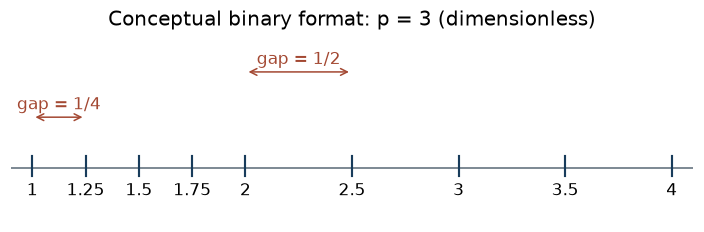

In [4]:
fig, ax = plt.subplots(figsize=(8, 2.2))
points = [1, 1.25, 1.5, 1.75, 2, 2.5, 3, 3.5, 4]
ax.axhline(0, color="#596875", lw=1)
for x in points:
    ax.plot([x, x], [-0.06, 0.09], color="#183C5B", lw=1.4)
    ax.text(x, -0.11, f"{x:g}", ha="center", va="top")
for a,b,y,label in [(1,1.25,.38,"gap = 1/4"),(2,2.5,.72,"gap = 1/2")]:
    ax.annotate("", xy=(a,y), xytext=(b,y), arrowprops={"arrowstyle":"<->", "color":"#A34832"})
    ax.text((a+b)/2,y+.06,label,ha="center",color="#A34832")
ax.set(xlim=(.9,4.1), ylim=(-.4,1), title="Conceptual binary format: p = 3 (dimensionless)")
ax.axis("off")
save_figure(fig, "A1组-G20-浮点间距")
plt.show()
plt.close(fig)


### 结果解释与讨论

加法表报告的是存储值相对准确0.3的误差，显示为0.3不意味着误差为零。求和实验中 $2^p$ 右侧间距为2；每次加1位于中点并舍回最低位为0的原值。先合并128个1后，所得增量可以精确表示，所以顺序影响结果。fsum追踪多个部分和，不能恢复输入转换之前已丢失的信息。

**自检。** 对binary64的 $10^{16}+1$，准确整数之和与浮点结果相差1，而相对误差很小。再手算 $(0.1101)_2=13/16$，解释为什么它能精确存储。数轴图为 $p=3$ 假想格式的概念示意，不是实际binary32/64的完整数轴。

## 1.2 截断误差与灾难性抵消（2学时）

**讲解与推导。** 对 $f\in C^2$，前向差分 $D_hf(x)=[f(x+h)-f(x)]/h$ 满足 $D_hf(x)-f'(x)=hf''(\xi)/2$。实际计算还会把分子已有绝对误差除以 $h$。在所述正常范围及小误差假设下，可用 $C_th+C_ru/h$ 作尺度估计；当两个常数为正时，平衡步长为 $\sqrt{C_ru/C_t}$。这是误差模型的最小点，未承诺实测曲线的精确极小点。

| 项目 | 本实验约定 |
| --- | --- |
| 理论预期 | 大 $x$ 的直接差额可能消失；有理化改善；缩小 $h$ 先降低截断影响，再放大有限精度影响。 |
| 输入与参数 | $x=1,10^4,10^8,10^{12},10^{16}$；$f=e^x$、求导点1；两种精度各扫描 $10^{-16}$ 至 $10^{-1}$ 的151个步长。 |
| 参考 | 准确十进制 $x$ 与实际存储 $\hat x$ 的100位有理化参考，120位复查；差分参考使用实际存储的 $h$。 |
| 指标与判据 | 同时报总误差与求值误差；曲线显示总误差、截断部分及有限精度部分的绝对值；检查输入塌缩而非固定实测最佳步长。 |
| 环境与预算 | CPU，确定性，无种子；302个差分点、10组差额比较；保留全扫描CSV，不只保留最佳点。 |

误差分解为 $\widehat D_h-e=(D_h^{ref}-e)+(\widehat D_h-D_h^{ref})$。两项有符号误差可能互相抵消，所以总误差绝对值不一定等于另外两项绝对值之和。

In [5]:
def experiment_12():
    results = {"cancellation": [], "derivative": [], "minima": []}
    with localcontext() as ctx:
        ctx.prec = 100
        for x_str in ["1", "1e4", "1e8", "1e12", "1e16"]:
            reference = difference_ref(x_str)
            assert abs(reference - difference_ref(x_str, 120)) < abs(reference) * Decimal("1e-90")
            for dtype in [np.float32, np.float64]:
                x = dtype(x_str)
                stored_x = dec(x)
                stored_reference = difference_ref(str(stored_x))
                assert abs(stored_reference - difference_ref(str(stored_x), 120)) < abs(stored_reference) * Decimal("1e-90")
                root_x = dtype(np.sqrt(x))
                root_x1 = dtype(np.sqrt(dtype(x + dtype(1))))
                direct = dtype(root_x1 - root_x)
                rational = dtype(dtype(1) / dtype(root_x1 + root_x))
                results["cancellation"].append({"x": x_str, "dtype": dtype.__name__, "reference": str(reference), "stored_input": str(stored_x), "stored_reference": str(stored_reference), "direct": float(direct), "rational": float(rational), "direct_error": metrics(direct, reference), "rational_error": metrics(rational, reference), "direct_error_at_stored": metrics(direct, stored_reference), "rational_error_at_stored": metrics(rational, stored_reference)})
        # Reference and truncation terms use high precision at the ACTUAL float h.
        reference_e = Decimal(1).exp()
        for dtype in [np.float32, np.float64]:
            series = []
            for exponent in np.linspace(-16, -1, 151):
                h = dtype(10.0 ** float(exponent))
                xp = dtype(dtype(1) + h)
                numerator = dtype(dtype(np.exp(xp)) - dtype(np.exp(dtype(1))))
                estimate = dtype(numerator / h)
                hd = dec(h)
                exact_difference = ((Decimal(1) + hd).exp() - reference_e) / hd
                trunc = abs(exact_difference - reference_e)
                rounding = abs(dec(estimate) - exact_difference)
                error = abs(dec(estimate) - reference_e)
                row = {"dtype": dtype.__name__, "h": float(h), "estimate": float(estimate), "error": float(error), "truncation": float(trunc), "rounding": float(rounding), "collapsed_input": bool(xp == dtype(1))}
                series.append(row)
            results["derivative"].extend(series)
            best = min(series, key=lambda row: row["error"])
            collapsed = [row["h"] for row in series if row["collapsed_input"]]
            results["minima"].append({**best, "largest_collapsed_h": max(collapsed)})
        zero = [row for row in results["cancellation"] if row["x"] == "1e16" and row["dtype"] == "float64"][0]
        assert zero["direct"] == 0 and zero["rational"] > 0
    print("Cancellation results:")
    print(json.dumps(results["cancellation"], ensure_ascii=False, indent=2))
    print("Derivative scan: 151 step sizes per dtype. Observed minima:")
    print(json.dumps(results["minima"], ensure_ascii=False, indent=2))
    for dtype in ["float32", "float64"]:
        lines = ["h,error,truncation,rounding"]
        lines += [f'{r["h"]:.17g},{r["error"]:.17g},{r["truncation"]:.17g},{r["rounding"]:.17g}' for r in results["derivative"] if r["dtype"] == dtype]
        (DATA / f"derivative_{dtype}.csv").write_text("\n".join(lines), encoding="utf-8")
    return results


r12 = quiet_run(experiment_12)
all_results["1.2"] = r12
show_table(["x", "dtype", "direct", "rational", "direct rel.error", "rational total rel.error", "rational eval. rel.error"], [[r["x"],r["dtype"],f'{r["direct"]:.7g}',f'{r["rational"]:.7g}',sci(r["direct_error"]["rel"],4),sci(r["rational_error"]["rel"],4),sci(r["rational_error_at_stored"]["rel"],4)] for r in r12["cancellation"]])
show_table(["dtype", "observed best h", "minimum absolute error", "largest collapsed h"], [[r["dtype"],sci(r["h"]),sci(r["error"]),sci(r["largest_collapsed_h"])] for r in r12["minima"]])


| x | dtype | direct | rational | direct rel.error | rational total rel.error | rational eval. rel.error |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | float32 | 0.4142135 | 0.4142135 | 5.8432E-8 | 5.8432E-8 | 5.8432E-8 |
| 1 | float64 | 0.4142136 | 0.4142136 | 2.3339E-16 | 9.9373E-17 | 9.9373E-17 |
| 1e4 | float32 | 0.004997253 | 0.004999875 | 5.2433E-4 | 1.6954E-8 | 1.6954E-8 |
| 1e4 | float64 | 0.004999875 | 0.004999875 | 2.1305E-13 | 1.7258E-17 | 1.7258E-17 |
| 1e8 | float32 | 0 | 5e-05 | 1.0000E+0 | 2.2762E-8 | 2.2762E-8 |
| 1e8 | float64 | 5e-05 | 5e-05 | 1.3618E-8 | 9.0114E-17 | 9.0114E-17 |
| 1e12 | float32 | 0 | 5e-07 | 1.0000E+0 | 2.5245E-9 | 4.5725E-9 |
| 1e12 | float64 | 5.000038e-07 | 5e-07 | 7.6145E-6 | 1.3173E-16 | 1.3173E-16 |
| 1e16 | float32 | 0 | 5e-09 | 1.0000E+0 | 6.0775E-9 | 7.5507E-9 |
| 1e16 | float64 | 0 | 5e-09 | 1.0000E+0 | 4.5923E-17 | 4.5923E-17 |

| dtype | observed best h | minimum absolute error | largest collapsed h |
| --- | --- | --- | --- |
| float32 | 1.584893E-4 | 2.352089E-5 | 5.011872E-8 |
| float64 | 1.000000E-8 | 6.602751E-9 | 1.000000E-16 |

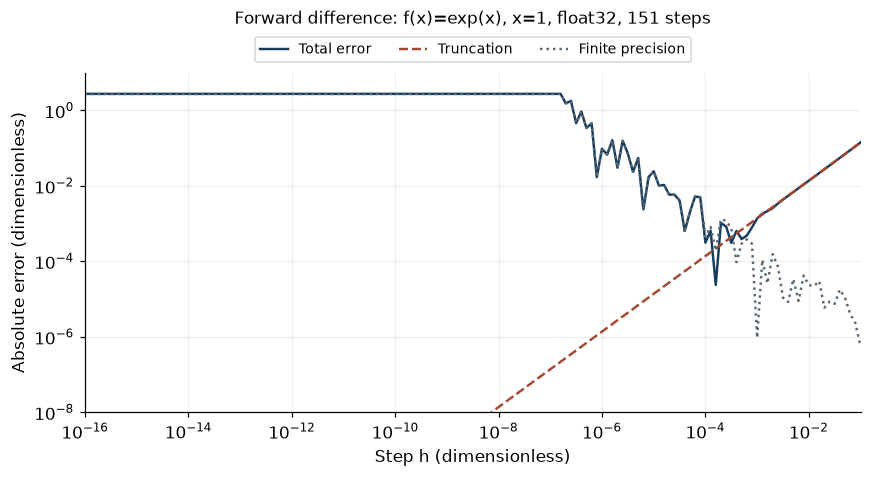

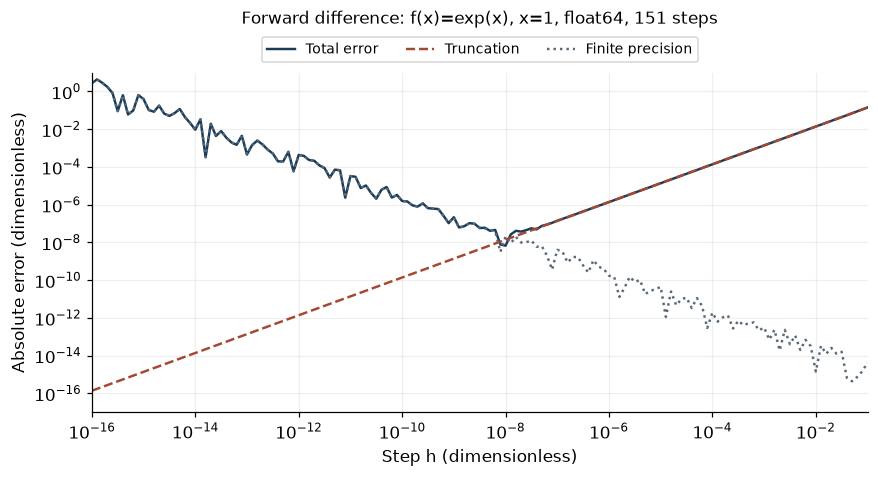

In [6]:
for dtype in ("float32", "float64"):
    rows = [r for r in r12["derivative"] if r["dtype"] == dtype]
    fig, ax = plt.subplots(figsize=(8.6,4.9))
    fig.subplots_adjust(left=.16,right=.98,bottom=.16,top=.79)
    for key,label,color,style in [("error","Total error","#183C5B","-"),("truncation","Truncation","#A34832","--"),("rounding","Finite precision","#596875",":")]:
        ax.loglog([r["h"] for r in rows],[r[key] for r in rows],label=label,color=color,ls=style,lw=1.6)
    ax.set(xlim=(1e-16,1e-1),ylim=(1e-8 if dtype == "float32" else 1e-17,10),xlabel="Step h (dimensionless)",ylabel="Absolute error (dimensionless)")
    ax.set_title(f"Forward difference: f(x)=exp(x), x=1, {dtype}, 151 steps",fontsize=11,pad=32)
    ax.grid(True,which="both",alpha=.2)
    ax.legend(loc="lower center",bbox_to_anchor=(.5,1.01),ncol=3,fontsize=9)
    save_figure(fig,"A1组-G20-差分-"+dtype)
    plt.show()
    plt.close(fig)


### 结果解释与讨论

从右向左读图表示 $h$ 减小：右侧主要受截断影响，谷底附近可能有带符号误差抵消，左侧受输入舍入与求值舍入影响。实际最佳点依赖平台和函数库，不应把它当成普适参数。对binary32，$x=10^{12}$ 或 $10^{16}$ 的输入本身还不准确，因此有理化的总误差与相对已存储输入的求值误差不同。

当 $1+h$ 已舍回1时，程序计算两个完全相同的指数，分子为零，导数估计也为零。减少截断误差的愿望不能恢复这个丢失的增量。

**自检。** 用有理化分母证明 $1/(2\sqrt{x+1})<d(x)<1/(2\sqrt x)$，排除零答案。最近舍入时 $0<h\le u$ 使 $1+h$ 舍回1；与扫描的最大塌缩步长比较。曲线中的“有限精度部分”包含输入舍入与函数库求值，不仅是最后一次减法。

## 1.3 条件数与稳定性（2学时）

**讲解与推导。** 对非零输入和非零输出，Taylor一阶展开给出 $\kappa_f(x)=|xf'(x)/f(x)|$。它描述准确输入扰动引起的准确输出变化。算法稳定性另研究计算过程额外放大的误差；同一目标的两个算法不能用各自输出互相作为真值。

对 $\log x$，$\kappa=1/|\log x|$；对开场差额，$\kappa_d=\tfrac12\sqrt{x/(x+1)}<1/2$。正积分族 $I_n=e^{-1}\int_0^1t^ne^t\,dt$ 满足 $e^{-1}/(n+1)<I_n<1/(n+1)$；分部积分得 $I_n=1-nI_{n-1}$。忽略新舍入时正向误差为 $(-1)^nn!\delta_0$，反向从末端 $N$ 到 $n$ 的误差为 $(-1)^{N-n}(n!/N!)\delta_N$。

| 项目 | 本实验约定 |
| --- | --- |
| 理论预期 | 对数在1.0001处放大相对扰动约10000倍；正向初值误差按阶乘放大，反向低阶值改善，给定末值本身不改善。 |
| 输入与参数 | $x=1.0001$、$\eta=10^{-8},10^{-7},10^{-6},10^{-5}$；积分阶0至9，正向初值0.6321、反向末值0.0684。 |
| 独立参考 | 高精度对数；积分正项级数 $e^{-1}\sum_{k\ge0}1/[k!(n+k+1)]$ 前160项，不使用递推作参考。 |
| 指标与判据 | 输入相对扰动、输出相对变化及放大率；积分的绝对误差与先验正性/范围。尾项界小于 $4.88\times10^{-288}$，另用120位核对舍入。 |
| 环境与预算 | CPU，确定性，无种子；4个扰动与10阶递推，分别保存两类证据。 |


In [7]:
def experiment_13():
    results = {"perturbation": [], "recurrence": [], "condition_difference": []}
    with localcontext() as ctx:
        ctx.prec = 100
        x0 = Decimal("1.0001")
        y0 = x0.ln()
        kappa = Decimal(1) / abs(y0)
        for delta_str in ["1e-8", "1e-7", "1e-6", "1e-5"]:
            delta = Decimal(delta_str)
            xp = x0 * (1 + delta)
            relative_output = abs((xp.ln() - y0) / y0)
            results["perturbation"].append({"relative_input": delta_str, "kappa": str(kappa), "relative_output": str(relative_output), "observed_amplification": str(relative_output / delta), "first_order": str(kappa * delta)})
        for x_str in ["1", "1e4", "1e8", "1e12", "1e16"]:
            x = Decimal(x_str)
            results["condition_difference"].append({"x": x_str, "kappa": str((x / (x + 1)).sqrt() / 2)})
        # Independent positive series: I_n = e^-1 sum_{k>=0} 1/[k! (n+k+1)].
        refs = []
        for n in range(10):
            factorial = Decimal(1)
            total = Decimal(0)
            for k in range(160):
                if k:
                    factorial *= k
                total += Decimal(1) / (factorial * Decimal(n + k + 1))
            refs.append((-Decimal(1)).exp() * total)
        forward = [0.6321]
        for n in range(1, 10):
            forward.append(1.0 - n * forward[-1])
        backward = [0.0] * 10
        backward[9] = 0.0684
        for n in range(9, 0, -1):
            backward[n - 1] = (1.0 - backward[n]) / n
        for n in range(10):
            results["recurrence"].append({"n": n, "reference": str(refs[n]), "forward": forward[n], "backward": backward[n], "forward_abs": str(abs(dec(forward[n]) - refs[n])), "backward_abs": str(abs(dec(backward[n]) - refs[n]))})
        assert forward[8] < 0 and all(x > 0 for x in backward)
        assert abs(dec(backward[0]) - refs[0]) < Decimal("1e-7")
    print(json.dumps(results, ensure_ascii=False, indent=2))
    return results


r13 = quiet_run(experiment_13)
all_results["1.3"] = r13
show_table(["relative input", "relative output", "first-order prediction", "amplification"], [[r["relative_input"],sci(r["relative_output"]),sci(r["first_order"]),f'{Decimal(r["observed_amplification"]):.5f}'] for r in r13["perturbation"]])
show_table(["n", "independent reference", "forward", "forward abs.error", "backward", "backward abs.error"], [[r["n"],f'{Decimal(r["reference"]):.10f}',f'{r["forward"]:.8f}',sci(r["forward_abs"]),f'{r["backward"]:.8f}',sci(r["backward_abs"])] for r in r13["recurrence"]])


| relative input | relative output | first-order prediction | amplification |
| --- | --- | --- | --- |
| 1e-8 | 1.000050E-4 | 1.000050E-4 | 10000.49994 |
| 1e-7 | 1.000050E-3 | 1.000050E-3 | 10000.49949 |
| 1e-6 | 1.000049E-2 | 1.000050E-2 | 10000.49499 |
| 1e-5 | 1.000045E-1 | 1.000050E-1 | 10000.44999 |

| n | independent reference | forward | forward abs.error | backward | backward abs.error |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.6321205588 | 0.63210000 | 2.055883E-5 | 0.63212062 | 6.396686E-8 |
| 1 | 0.3678794412 | 0.36790000 | 2.055883E-5 | 0.36787938 | 6.396686E-8 |
| 2 | 0.2642411177 | 0.26420000 | 4.111766E-5 | 0.26424125 | 1.279337E-7 |
| 3 | 0.2072766470 | 0.20740000 | 1.233530E-4 | 0.20727626 | 3.838011E-7 |
| 4 | 0.1708934119 | 0.17040000 | 4.934119E-4 | 0.17089495 | 1.535205E-6 |
| 5 | 0.1455329406 | 0.14800000 | 2.467059E-3 | 0.14552526 | 7.676023E-6 |
| 6 | 0.1268023566 | 0.11200000 | 1.480236E-2 | 0.12684841 | 4.605614E-5 |
| 7 | 0.1123835041 | 0.21600000 | 1.036165E-1 | 0.11206111 | 3.223930E-4 |
| 8 | 0.1009319674 | -0.72800000 | 8.289320E-1 | 0.10351111 | 2.579144E-3 |
| 9 | 0.0916122930 | 7.55200000 | 7.460388E+0 | 0.06840000 | 2.321229E-2 |

### 结果解释与讨论

对数的输入扰动表对应问题敏感性；高精度计算仍能看见输出的大相对变化，它不是浮点舍入造成的假象。积分算法表对应误差传播；正向8阶的负值违背积分的正性，9阶值还超出先验上界。反向低阶积分更准确，因为末值误差逐步除以整数，但9阶输出仍是原先给定的粗值。

**自检。** 当 $\kappa=10^4$、输入相对误差约 $10^{-6}$ 时，输出的一阶相对误差约 $10^{-2}$；若目标为 $10^{-3}$，需要更准确的数据，而不只是更多运算位。积分定义与“任意初值到递推序列”的映射采用不同输入模型，不能混为同一条件性问题。

## 1.4 AI关联：训练中的数值问题（2学时）

**讲解与推导。** 有限非空logits $z$ 的Softmax为 $p_i=e^{z_i}/\sum_je^{z_j}$。令 $m=\max z_j$，同时除以 $e^m$ 得 $p_i=e^{z_i-m}/\sum_je^{z_j-m}$；指数在 $(0,1]$ 内，且至少一个为1，所以实数分母在 $[1,n]$。对数概率宜直接算 $(z_i-m)-\log\sum_je^{z_j-m}$，交叉熵是它的负值。

| 项目 | 本实验约定 |
| --- | --- |
| 理论预期 | 大正偏移使直接指数上溢，大负偏移使指数全下溢；平移版三组输出相同且有限，尾概率仍可能为零。 |
| 输入与参数 | $(0,1,2)$、$(1000,1001,1002)$、$(-1000,-999,-998)$；尾部输入 $(0,-1000)$，真实类别为第2类；另测 $10^{-7},10^{-8}$ 梯度的binary16存储。 |
| 独立参考 | 准确整数logits的100位Decimal概率，120位复查；梯度参考为准确十进制量；不拿概率和为1作准确性证明。 |
| 指标与判据 | 全有限、最大分量绝对误差 $E_\infty$、高精度累加存储概率的归一化偏差 $E_\Sigma$；尾部两种损失路径。三维测试容差为binary32 $10^{-6}$、binary64 $10^{-14}$，不推广到任意维数。 |
| 环境与预算 | CPU，确定性，无种子，函数级计算；上溢/下溢只在局部故意演示中处理告警，并断言预期失败。没有运行完整训练。 |

损失梯度为 $\partial\ell/\partial z_j=p_j-\mathbf1_{j=y}$。缩放必须发生在小梯度被低精度存储之前，并在更新前还原；不能把已经舍为零的数事后放大。

In [8]:
def experiment_14():
    results = {"softmax": [], "tail": [], "gradients": []}
    with localcontext() as ctx:
        ctx.prec = 100
        cases = [("ordinary", [0, 1, 2]), ("overflow", [1000, 1001, 1002]), ("underflow", [-1000, -999, -998])]
        for label, inputs in cases:
            ref, lse_ref = softmax_ref(inputs)
            assert all(abs(a - b) < Decimal("1e-90") for a, b in zip(ref, softmax_ref(inputs, 120)[0]))
            for dtype in [np.float32, np.float64]:
                z = np.array(inputs, dtype=dtype)
                with np.errstate(over="ignore", under="ignore", invalid="ignore", divide="ignore"):
                    naive_exp = np.exp(z)
                    naive = naive_exp / np.sum(naive_exp, dtype=dtype)
                    shifted = np.exp(z - np.max(z))
                    stable = shifted / np.sum(shifted, dtype=dtype)
                    m = np.max(z)
                    log_probs = (z - m) - np.log(np.sum(shifted, dtype=dtype))
                    lse = dtype(m + np.log(np.sum(shifted, dtype=dtype)))
                component_error = max(abs(dec(x) - y) for x, y in zip(stable, ref))
                normalization = abs(sum(dec(x) for x in stable) - Decimal(1))
                results["softmax"].append({"case": label, "inputs": inputs, "dtype": dtype.__name__, "naive": [str(float(x)) for x in naive], "naive_finite": bool(np.all(np.isfinite(naive))), "stable": [float(x) for x in stable], "stable_finite": bool(np.all(np.isfinite(stable))), "normalization_error": str(normalization), "max_abs_error": str(component_error), "lse": float(lse), "lse_abs_error": str(abs(dec(lse) - lse_ref)), "class0_loss": float(-log_probs[0])})
                assert np.all(np.isfinite(stable)) and component_error < Decimal("1e-6")
        tail_inputs = [0, -1000]
        ref, _ = softmax_ref(tail_inputs)
        for dtype in [np.float32, np.float64]:
            z = np.array(tail_inputs, dtype=dtype)
            m = np.max(z)
            with np.errstate(under="ignore", divide="ignore"):
                w = np.exp(z - m)
                p = w / np.sum(w, dtype=dtype)
                probability_loss = -np.log(p[1])
                log_probability_loss = -((z[1] - m) - np.log(np.sum(w, dtype=dtype)))
            results["tail"].append({"dtype": dtype.__name__, "p_tail": float(p[1]), "reference_tail": str(ref[1]), "probability_loss": str(float(probability_loss)), "log_probability_loss": float(log_probability_loss)})
            assert p[1] == 0 and log_probability_loss == 1000
        for value in ["1e-7", "1e-8"]:
            g = np.float16(value)
            with np.errstate(under="ignore"):
                stored_update = np.float16(np.float16(1) - np.float16(Decimal("0.01")) * g)
                scaled = np.float16(Decimal(value) * 1024)
            restored = np.float32(scaled) / np.float32(1024)
            results["gradients"].append({"exact_g": value, "float16_g": float(g), "scaled_stored": float(scaled), "unscaled_float32": float(restored), "stored_parameter_after_update": float(stored_update)})
    print(json.dumps(results, ensure_ascii=False, indent=2))
    return results


r14 = quiet_run(experiment_14)
all_results["1.4"] = r14
show_table(["case", "dtype", "naive finite", "shifted finite", "max abs.error", "normalization error", "class-1 loss"], [[r["case"],r["dtype"],r["naive_finite"],r["stable_finite"],sci(r["max_abs_error"]),sci(r["normalization_error"]),f'{r["class0_loss"]:.8f}'] for r in r14["softmax"]])
show_table(["dtype", "stored tail probability", "probability-path loss", "log-path loss"], [[r["dtype"],r["p_tail"],r["probability_loss"],r["log_probability_loss"]] for r in r14["tail"]])
show_table(["exact gradient", "float16 stored", "scale/unscale float32", "float16 parameter after update"], [[r["exact_g"],r["float16_g"],r["unscaled_float32"],r["stored_parameter_after_update"]] for r in r14["gradients"]])
assert all(not r["naive_finite"] for r in r14["softmax"] if r["case"] != "ordinary")
assert all(Decimal(r["max_abs_error"]) < (Decimal("1e-6") if r["dtype"] == "float32" else Decimal("1e-14")) for r in r14["softmax"])


| case | dtype | naive finite | shifted finite | max abs.error | normalization error | class-1 loss |
| --- | --- | --- | --- | --- | --- | --- |
| ordinary | float32 | True | True | 1.234297E-8 | 2.235174E-8 | 2.40760612 |
| ordinary | float64 | True | True | 1.045442E-16 | 1.110223E-16 | 2.40760596 |
| overflow | float32 | False | True | 1.234297E-8 | 2.235174E-8 | 2.40760612 |
| overflow | float64 | False | True | 1.045442E-16 | 1.110223E-16 | 2.40760596 |
| underflow | float32 | False | True | 1.234297E-8 | 2.235174E-8 | 2.40760612 |
| underflow | float64 | False | True | 1.045442E-16 | 1.110223E-16 | 2.40760596 |

| dtype | stored tail probability | probability-path loss | log-path loss |
| --- | --- | --- | --- |
| float32 | 0.0 | inf | 1000.0 |
| float64 | 0.0 | inf | 1000.0 |

| exact gradient | float16 stored | scale/unscale float32 | float16 parameter after update |
| --- | --- | --- | --- |
| 1e-7 | 1.1920928955078125e-07 | 1.00000761449337e-07 | 1.0 |
| 1e-8 | 0.0 | 1.0011717677116394e-08 | 1.0 |

### 结果解释与讨论

共同的大偏移不会改变准确概率，却会改变直接指数的范围。减最大值避免本题的范围失效，但不保证每次测试的每一项误差都更小。尾部例子中概率是 $(1,0)$，其和为1且全部有限；先取第二类负对数却为正无穷，直接对数路径仍给出约1000。需要的损失信息可保留，即使极小概率无法被当前格式表示。

本题演示建议是教学构造，不是某个AI的真实引语。无NaN仍可能有无穷值，输出有限仍可能不准确，loss下降也不证明梯度和更新量正确。标量缩放实验只验证低精度存储中的一个环节，不构成完整训练稳定性的证明。

**自检。** 解释为什么必须先缩放再存储，并在较高精度中还原；再比较更新量与参数附近的浮点间距。梯度没有变成零，参数更新仍可能被舍入吸收。

## 课后习题数值核验

以下四个单元对应[课后习题](A1组-习题.md)，提供已运行的数值证据；完整推导和辨析另见[A1组-习题参考解答.md](A1组-习题参考解答.md)。它们属于参考核验材料，不增加四节课堂学时，也不代表学生独立完成习题。先独立尝试题面，再对照输出。

In [9]:
from math import factorial
core = SimpleNamespace(experiment_13=experiment_13, experiment_14=experiment_14, softmax_ref=softmax_ref)
def dfloat(value):
    return Decimal.from_float(float(value))


### 题1：数值核验

参考由准确输入、高精度运算和独立数学表达式建立。题1的误差口径与验收标准见题面，程序在下方显示全套实测指标，并将未缩写值保存到 `A1组-结果/exercise_results.json`。

In [10]:
def exercise_1():
    rows = []
    with localcontext() as ctx:
        ctx.prec = 100
        ref = Decimal("0.2")
        for dtype in (np.float32, np.float64):
            value = dtype("0.2")
            signed = dfloat(value) - ref
            rows.append({
                "dtype": dtype.__name__, "stored_exact": str(dfloat(value)),
                "signed_error": str(signed), "absolute_error": str(abs(signed)),
                "relative_error": str(abs(signed) / ref),
                "display": format(float(value), ".1f"),
            })
    assert rows[0]["signed_error"].startswith("2.98023223876953125E-9")
    assert rows[1]["signed_error"].startswith("1.110223024625156540423")
    return rows


result = exercise_1()
exercise_results["exercise_1"] = result
show_table(["dtype", "stored exact", "signed error", "abs.error", "rel.error"], [[r["dtype"],r["stored_exact"],sci(r["signed_error"]),sci(r["absolute_error"]),sci(r["relative_error"])] for r in result])

| dtype | stored exact | signed error | abs.error | rel.error |
| --- | --- | --- | --- | --- |
| float32 | 0.20000000298023223876953125 | 2.980232E-9 | 2.980232E-9 | 1.490116E-8 |
| float64 | 0.200000000000000011102230246251565404236316680908203125 | 1.110223E-17 | 1.110223E-17 | 5.551115E-17 |

### 题2：数值核验

参考由准确输入、高精度运算和独立数学表达式建立。题2的误差口径与验收标准见题面，程序在下方显示全套实测指标，并将未缩写值保存到 `A1组-结果/exercise_results.json`。

In [11]:
def exercise_2():
    cancellation = []
    difference = []
    hs = ("1e-1", "1e-4", "1e-8", "1e-12", "1e-16")
    with localcontext() as ctx:
        ctx.prec = 100
        for dtype, power in ((np.float32, 24), (np.float64, 53)):
            x = dtype(2**power)
            direct = dtype(np.sqrt(dtype(x + dtype(1))) - np.sqrt(x))
            rational = dtype(dtype(1) / dtype(np.sqrt(dtype(x + dtype(1))) + np.sqrt(x)))
            ref = Decimal(1) / ((Decimal(2**power) + 1).sqrt() + Decimal(2**power).sqrt())
            with localcontext() as check:
                check.prec = 120
                ref120 = Decimal(1) / ((Decimal(2**power) + 1).sqrt() + Decimal(2**power).sqrt())
            assert abs(ref - ref120) < abs(ref) * Decimal("1e-95")
            cancellation.append({
                "dtype": dtype.__name__, "x": 2**power, "reference": str(ref),
                "direct": float(direct), "direct_absolute_error": str(abs(dfloat(direct) - ref)),
                "rational": float(rational), "rational_absolute_error": str(abs(dfloat(rational) - ref)),
            })
            e = Decimal(1).exp()
            with localcontext() as check:
                check.prec = 120
                assert abs(e - Decimal(1).exp()) < Decimal("1e-95")
            for h_text in hs:
                h = dtype(h_text)
                xp = dtype(dtype(1) + h)
                num = dtype(dtype(np.exp(xp)) - dtype(np.exp(dtype(1))))
                dh = dtype(num / h)
                difference.append({
                    "dtype": dtype.__name__, "h_requested": h_text, "h_stored": float(h),
                    "estimate": float(dh), "absolute_error": str(abs(dfloat(dh) - e)),
                    "collapsed_input": bool(xp == dtype(1)),
                })
    assert all(row["direct"] == 0 for row in cancellation)
    return {"cancellation": cancellation, "difference": difference}


result = exercise_2()
exercise_results["exercise_2"] = result
show_table(["dtype", "x", "reference", "direct", "direct abs.error", "rational", "rational abs.error"], [[r["dtype"],r["x"],sci(r["reference"],12),r["direct"],sci(r["direct_absolute_error"]),r["rational"],sci(r["rational_absolute_error"])] for r in result["cancellation"]])
show_table(["dtype", "requested h", "stored h", "D_h", "abs.error", "collapsed input"], [[r["dtype"],r["h_requested"],f'{r["h_stored"]:.17g}',f'{r["estimate"]:.12g}',sci(r["absolute_error"]),r["collapsed_input"]] for r in result["difference"]])

| dtype | x | reference | direct | direct abs.error | rational | rational abs.error |
| --- | --- | --- | --- | --- | --- | --- |
| float32 | 16777216 | 1.220703106810E-4 | 0.0 | 1.220703E-4 | 0.0001220703125 | 1.818989E-12 |
| float64 | 9007199254740992 | 5.268356063862E-9 | 0.0 | 5.268356E-9 | 5.2683560638617535e-09 | 3.208196E-25 |

| dtype | requested h | stored h | D_h | abs.error | collapsed input |
| --- | --- | --- | --- | --- | --- |
| float32 | 1e-1 | 0.10000000149011612 | 2.85884141922 | 1.405596E-1 | False |
| float32 | 1e-4 | 9.9999997473787516e-05 | 2.71797180176 | 3.100267E-4 | False |
| float32 | 1e-8 | 9.9999999392252903e-09 | 0 | 2.718282E+0 | True |
| float32 | 1e-12 | 9.999999960041972e-13 | 0 | 2.718282E+0 | True |
| float32 | 1e-16 | 1.0000000168623835e-16 | 0 | 2.718282E+0 | True |
| float64 | 1e-1 | 0.10000000000000001 | 2.85884195487 | 1.405601E-1 | False |
| float64 | 1e-4 | 0.0001 | 2.71841774708 | 1.359186E-4 | False |
| float64 | 1e-8 | 1e-08 | 2.71828182186 | 6.602751E-9 | False |
| float64 | 1e-12 | 9.9999999999999998e-13 | 2.7187141427 | 4.323142E-4 | False |
| float64 | 1e-16 | 9.9999999999999998e-17 | 0 | 2.718282E+0 | True |

### 题3：数值核验

参考由准确输入、高精度运算和独立数学表达式建立。题3的误差口径与验收标准见题面，程序在下方显示全套实测指标，并将未缩写值保存到 `A1组-结果/exercise_results.json`。

In [12]:
def exercise_3():
    with contextlib.redirect_stdout(io.StringIO()):
        raw = core.experiment_13()
    tail_bounds = []
    with localcontext() as check:
        check.prec = 120
        for row in raw["recurrence"]:
            if row["n"] not in (0, 8, 9):
                continue
            n = row["n"]
            total = Decimal(0)
            fact = 1
            for k in range(160):
                if k:
                    fact *= k
                total += Decimal(1) / (Decimal(fact) * Decimal(n + k + 1))
            ref120 = (-Decimal(1)).exp() * total
            assert abs(ref120 - Decimal(row["reference"])) < Decimal("1e-95")
            remainder_bound = ((-Decimal(1)).exp()
                               / Decimal(factorial(160) * (n + 161))
                               / (1 - Decimal(1) / 161))
            assert remainder_bound < Decimal("4.88e-288")
            tail_bounds.append({"n": n, "terms": 160,
                                "term_ratio_upper_bound": "1/161",
                                "remainder_upper_bound": str(remainder_bound)})
    return {
        "condition": [{k: row[k] for k in ("relative_input", "relative_output", "first_order", "observed_amplification")} for row in raw["perturbation"] if row["relative_input"] in ("1e-8", "1e-6")],
        "recurrence": [{k: row[k] for k in ("n", "reference", "forward", "backward", "forward_abs", "backward_abs")} for row in raw["recurrence"] if row["n"] in (0, 8, 9)],
        "tail_bounds": tail_bounds,
    }


result = exercise_3()
exercise_results["exercise_3"] = result
show_table(["n", "reference", "forward abs.error", "backward abs.error"], [[r["n"],f'{Decimal(r["reference"]):.12f}',sci(r["forward_abs"]),sci(r["backward_abs"])] for r in result["recurrence"]])
show_table(["n", "number of terms", "tail upper bound"], [[r["n"],r["terms"],sci(r["remainder_upper_bound"])] for r in result["tail_bounds"]])

| n | reference | forward abs.error | backward abs.error |
| --- | --- | --- | --- |
| 0 | 0.632120558829 | 2.055883E-5 | 6.396686E-8 |
| 8 | 0.100931967446 | 8.289320E-1 | 2.579144E-3 |
| 9 | 0.091612292990 | 7.460388E+0 | 2.321229E-2 |

| n | number of terms | tail upper bound |
| --- | --- | --- |
| 0 | 160 | 4.876737E-288 |
| 8 | 160 | 4.645885E-288 |
| 9 | 160 | 4.618556E-288 |

### 题4：数值核验

参考由准确输入、高精度运算和独立数学表达式建立。题4的误差口径与验收标准见题面，程序在下方显示全套实测指标，并将未缩写值保存到 `A1组-结果/exercise_results.json`。

In [13]:
def exercise_4():
    with contextlib.redirect_stdout(io.StringIO()):
        raw = core.experiment_14()
    rows = []
    with localcontext() as ctx:
        ctx.prec = 100
        for measured in raw["softmax"]:
            row = {k: measured[k] for k in ("case", "dtype", "naive_finite", "stable_finite", "normalization_error", "max_abs_error")}
            row["naive_values"] = measured["naive"]
            if measured["naive_finite"]:
                reference, _ = core.softmax_ref(measured["inputs"])
                # Core stores round-trip representations of Python floats.
                # Recover their exact stored values before accumulating errors.
                stored = [dfloat(float(value)) for value in measured["naive"]]
                row["naive_max_abs_error"] = str(max(abs(v - r) for v, r in zip(stored, reference)))
                row["naive_normalization_error"] = str(abs(sum(stored) - Decimal(1)))
            else:
                row["naive_max_abs_error"] = "NaN"
                row["naive_normalization_error"] = "NaN"
            rows.append(row)
    assert not np.isnan(np.inf) and not np.isfinite(np.inf)
    assert not np.isnan(-np.inf) and not np.isfinite(-np.inf)
    return {
        "softmax": rows,
        "tail": raw["tail"],
        "nonfinite_demo": {"isnan_positive_infinity": bool(np.isnan(np.inf)),
                           "isfinite_positive_infinity": bool(np.isfinite(np.inf))},
    }


result = exercise_4()
exercise_results["exercise_4"] = result
rows=[]
for r in result["softmax"]:
    rows.append([r["case"],r["dtype"],"direct",r["naive_finite"],sci(r["naive_max_abs_error"]),sci(r["naive_normalization_error"])])
    rows.append([r["case"],r["dtype"],"shifted",r["stable_finite"],sci(r["max_abs_error"]),sci(r["normalization_error"])])
show_table(["case", "dtype", "implementation", "finite", "max abs.error", "normalization error"],rows)
show_table(["dtype", "tail probability", "probability-path loss", "log-path loss"],[[r["dtype"],r["p_tail"],r["probability_loss"],r["log_probability_loss"]] for r in result["tail"]])
print("Infinity checks:", result["nonfinite_demo"])

| case | dtype | implementation | finite | max abs.error | normalization error |
| --- | --- | --- | --- | --- | --- |
| ordinary | float32 | direct | True | 1.965546E-8 | 7.450581E-9 |
| ordinary | float32 | shifted | True | 1.234297E-8 | 2.235174E-8 |
| ordinary | float64 | direct | True | 1.084679E-17 | 0.000000E-49 |
| ordinary | float64 | shifted | True | 1.045442E-16 | 1.110223E-16 |
| overflow | float32 | direct | False | NaN | NaN |
| overflow | float32 | shifted | True | 1.234297E-8 | 2.235174E-8 |
| overflow | float64 | direct | False | NaN | NaN |
| overflow | float64 | shifted | True | 1.045442E-16 | 1.110223E-16 |
| underflow | float32 | direct | False | NaN | NaN |
| underflow | float32 | shifted | True | 1.234297E-8 | 2.235174E-8 |
| underflow | float64 | direct | False | NaN | NaN |
| underflow | float64 | shifted | True | 1.045442E-16 | 1.110223E-16 |

| dtype | tail probability | probability-path loss | log-path loss |
| --- | --- | --- | --- |
| float32 | 0.0 | inf | 1000.0 |
| float64 | 0.0 | inf | 1000.0 |

Infinity checks: {'isnan_positive_infinity': False, 'isfinite_positive_infinity': False}


## 选读例子的运行核验

秦九韶算法与开方迭代的完整推导见[正文附录](#ch01-sec-horner)。这里实际运行有限步骤求值及迭代，与独立高精度参考比较。多项式系数中的缺项必须补零，停止迭代不能只检查显示位数。本部分为选读，不扩大8学时范围。

In [14]:
def horner(coefficients, x):
    value = coefficients[0]
    for coefficient in coefficients[1:]:
        value = value * x + coefficient
    return value
with localcontext() as ctx:
    ctx.prec = 100
    ref = Decimal(3).sqrt()
    x = 2.0
    newton = []
    for k in range(5):
        newton.append({"k": k, "x": x, "abs_error": str(abs(dec(x) - ref))})
        x = 0.5 * (x + 3.0 / x)
all_results["appendix"] = {"newton": newton, "horner": horner([2.0,0.0,-3.0,3.0,-4.0],-2.0), "horner_derivative": horner([2.0,-4.0,5.0,-7.0],-2.0), "polynomial_exercise": horner([3,0,-2,0,1,7],3)}
assert all_results["appendix"]["horner"] == 10.0
assert all_results["appendix"]["horner_derivative"] == -49.0
assert all_results["appendix"]["polynomial_exercise"] == 685
assert Decimal(newton[-1]["abs_error"]) < Decimal("3e-16")
show_table(["iteration", "stored x", "absolute error"], [[r["k"],f'{r["x"]:.16f}',sci(r["abs_error"])] for r in newton])
print("Horner:",all_results["appendix"]["horner"],"Derivative:",all_results["appendix"]["horner_derivative"])


| iteration | stored x | absolute error |
| --- | --- | --- |
| 0 | 2.0000000000000000 | 2.679492E-1 |
| 1 | 1.7500000000000000 | 1.794919E-2 |
| 2 | 1.7321428571428572 | 9.204957E-5 |
| 3 | 1.7320508100147274 | 2.445850E-9 |
| 4 | 1.7320508075688772 | 1.003508E-16 |

Horner: 10.0 Derivative: -49.0


## 回到开场与本章小结

开场数学问题对 $x$ 的局部相对条件数小于1/2；直接路径的零答案来自 $x+1$ 的舍入与求值顺序。有理化让同一目标采用更可靠的计算过程。相信计算结果需要同时说明数据准确性、问题敏感性、算法误差和独立参考，不能只凭输出的位数、归一化、无NaN或某个AI的赞同。

全部结果、输入与环境将在最后一个代码单元保存。误差曲线对应实际扫描CSV；没有跳过故意失败的演示，也没有从旧Notebook复制输出冒充本次运行。

In [15]:
environment["elapsed_seconds"] = time.perf_counter() - started
exercise_results["environment"] = dict(environment)
for filename, obj in [("results.json", all_results), ("exercise_results.json", exercise_results), ("environment.json", environment)]:
    (DATA / filename).write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Saved all numerical evidence to A1组-结果/.")
print("Actual elapsed seconds:", environment["elapsed_seconds"])


Saved all numerical evidence to A1组-结果/.
Actual elapsed seconds: 0.9847219999937806
